In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [27]:
transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(0.5,))
])

train_dataset = datasets.MNIST(
    root='data',
    train=True,
    transform=transforms,
    download=True
)

test_dataset = datasets.MNIST(
    root='data',
    train=False,
    transform=transforms,
    download=True
)

In [28]:
len(train_dataset)

60000

In [29]:
len(test_dataset)

10000

In [30]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [31]:
data_iter = iter(train_loader)
images, labels = next(data_iter)

print(images.shape)  # Should print torch.Size([64, 3, 32, 32]) (or whatever channels/size you set)
print(labels.shape)  # Should print torch.Size([64])

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [32]:
images[0].squeeze().shape

torch.Size([28, 28])

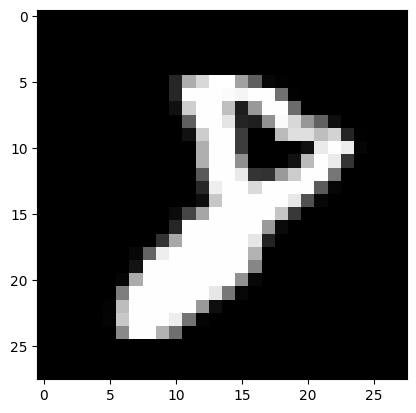

In [33]:
plt.imshow(images[0].squeeze(), cmap='gray')
plt.show()

In [34]:
labels[0]

tensor(8)

In [35]:
class DigitClassifier(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [36]:
model = DigitClassifier()

optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [37]:
epochs = 5

for epoch in range(epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        # 1. Froward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item()

        # 2. Backword pass
        optimizer.zero_grad()
        loss.backward()

        # 3. Weight updates
        optimizer.step()
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss / len(train_loader):.2f}")

Epoch [1/5], Loss: 0.39
Epoch [2/5], Loss: 0.19
Epoch [3/5], Loss: 0.14
Epoch [4/5], Loss: 0.11
Epoch [5/5], Loss: 0.10


In [38]:
model.eval()

total = 0
correct = 0

with torch.no_grad():
    for images, lables in test_loader:
        output = model(images)
        _, predicted = torch.max(output, 1)

        print(predicted)
        print(lables)

        print((predicted == lables).sum().item())
        break

tensor([7, 2, 1, 0, 4, 1, 4, 9, 6, 4, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2, 3, 5, 1, 2,
        4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5, 7, 8, 9, 3])
tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2, 3, 5, 1, 2,
        4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5, 7, 8, 9, 3])
62


## Classification Report and Confusion Matrix

In [42]:
from sklearn.metrics import classification_report

all_labels = []
all_predicted = []

model.eval()  # Set model to evaluation mode
with torch.no_grad():
    for images, labels in test_loader:
        # Move to device if using GPU
        # images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        # Extend lists with batch items converted to Python scalars/integers
        all_labels.extend(labels.tolist())
        all_predicted.extend(predicted.tolist())

# Verify lengths match 10,000
print(f"Total collected labels: {len(all_labels)}")
print(f"Total collected predictions: {len(all_predicted)}")

# Now generate the report safely
report = classification_report(all_labels, all_predicted)
print(report)

Total collected labels: 10000
Total collected predictions: 10000
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       980
           1       0.98      0.98      0.98      1135
           2       0.96      0.98      0.97      1032
           3       0.97      0.96      0.97      1010
           4       0.89      0.98      0.93       982
           5       0.98      0.94      0.96       892
           6       0.94      0.98      0.96       958
           7       0.96      0.95      0.96      1028
           8       0.92      0.97      0.95       974
           9       0.99      0.85      0.92      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [43]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(all_labels, all_predicted)
cm

array([[ 952,    0,    3,    0,    0,    3,   16,    1,    4,    1],
       [   0, 1115,    5,    1,    0,    0,    3,    1,   10,    0],
       [   1,    0, 1010,    1,    3,    0,    5,    4,    8,    0],
       [   0,    0,   10,  974,    0,    4,    0,   10,   11,    1],
       [   0,    0,    1,    0,  962,    1,   14,    1,    3,    0],
       [   1,    0,    0,   16,    1,  842,   14,    1,   16,    1],
       [   2,    2,    0,    1,    3,    2,  937,    0,   11,    0],
       [   2,   10,   18,    2,    6,    1,    1,  981,    4,    3],
       [   0,    0,    5,    5,    4,    2,    6,    4,  947,    1],
       [   3,    5,    2,    7,  100,    4,    1,   14,   11,  862]])

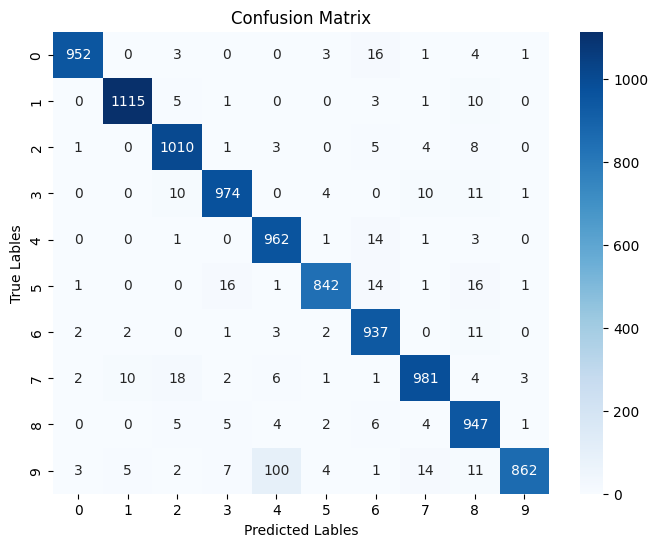

In [45]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(len(cm)), yticklabels=range(len(cm)))
plt.xlabel("Predicted Lables")
plt.ylabel("True Lables")
plt.title("Confusion Matrix")
plt.show()